Setup

In [3]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

from weather_shift.data import get_pairs, load_label
from weather_shift.metrics import error_detection, reliability
from weather_shift.model import predict, predict_flip

name = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024"
processor = SegformerImageProcessor.from_pretrained(name)
model = SegformerForSemanticSegmentation.from_pretrained(name).eval()

Loading weights: 100%|██████████| 208/208 [00:00<00:00, 10361.72it/s]


In [5]:
palette = np.array([
    [128, 64, 128],   # 0 - road
    [244, 35, 232],   # 1 - sidewalk
    [70, 70, 70],     # 2 - building
    [102, 102, 156],  # 3 - wall
    [190, 153, 153],  # 4 - fence
    [153, 153, 153],  # 5 - pole
    [250, 170, 30],   # 6 - traffic light
    [220, 220, 0],    # 7 - traffic sign
    [107, 142, 35],   # 8 - vegetation
    [152, 251, 152],  # 9 - terrain
    [70, 130, 180],   # 10 - sky
    [220, 20, 60],    # 11 - person
    [255, 0, 0],      # 12 - rider
    [0, 0, 142],      # 13 - car
    [0, 0, 70],       # 14 - truck
    [0, 60, 100],     # 15 - bus
    [0, 80, 100],     # 16 - train
    [0, 0, 230],      # 17 - motorcycle
    [119, 11, 32]    # 18 - bicycle
], dtype=np.uint8)

# add a 20th colour (black) for "ignore"
palette_ext = np.vstack([palette, [0, 0, 0]])

In [ ]:
night = get_pairs("../data", "acdc", "night")
img_path, label_path = night[0]

image = Image.open(img_path).convert("RGB")
label = load_label(label_path)
pred, conf = predict(image, processor, model)

valid = label != 255
c = conf[valid]
correct = pred[valid] == label[valid]

bin = np.linspace(0, 1, 11)
for lo , hi in zip(bin[:-1], bin[1:], strict=True):
    in_bin = (c >= lo) & (c <= hi)
    if in_bin.sum() > 0:
        print(f"{lo:.1f}-{hi:.1f}: {in_bin.sum():9d} pixels |"
              f"avg confidence: {c[in_bin].mean():.2f} |"
              f"accuracy : {correct[in_bin].mean():.2f}")

0.1-0.2:         6 pixels |avg confidence: 0.19 |accuracy : 0.00
0.2-0.3:      6816 pixels |avg confidence: 0.27 |accuracy : 0.07
0.3-0.4:     33950 pixels |avg confidence: 0.36 |accuracy : 0.09
0.4-0.5:     64644 pixels |avg confidence: 0.46 |accuracy : 0.19
0.5-0.6:    180778 pixels |avg confidence: 0.55 |accuracy : 0.32
0.6-0.7:    198339 pixels |avg confidence: 0.65 |accuracy : 0.27
0.7-0.8:    238693 pixels |avg confidence: 0.75 |accuracy : 0.22
0.8-0.9:    244249 pixels |avg confidence: 0.85 |accuracy : 0.31
0.9-1.0:    916828 pixels |avg confidence: 0.98 |accuracy : 0.71


100%|██████████| 106/106 [00:47<00:00,  2.21it/s]


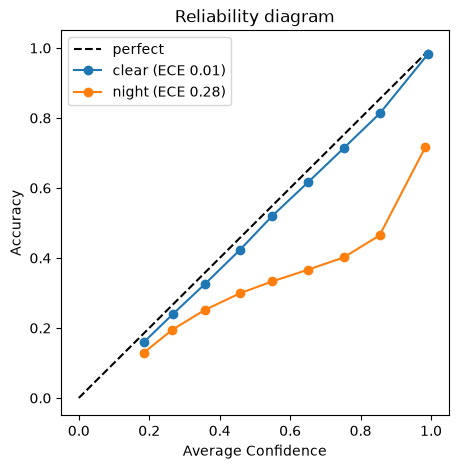

In [7]:
# reliability diagram
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", label="perfect")
for name, pairs in [("clear", get_pairs("../data", "cityscapes")),
                    ("night", get_pairs("../data", "acdc", "night"))]:
    count, avg_conf, acc = reliability(pairs, processor, model)
    # Expected Calibration Error
    ece = np.sum(count / count.sum() * np.abs(avg_conf - acc))
    ax.plot(avg_conf, acc, "o-", label = f"{name} (ECE {ece:.2f})")
ax.set_xlabel("Average Confidence")
ax.set_ylabel("Accuracy")
ax.set_title("Reliability diagram")
ax.legend()
plt.savefig("../reports/figures/week3_reliability_clear_night.png", dpi=150)
plt.show()

In [8]:
sets = {"clear": get_pairs("../data", "cityscapes")}
for cond in ["fog", "night", "rain", "snow"]:
    sets[cond] = get_pairs("../data", "acdc", cond)

rows = []
for name, pairs in sets.items():
    count, avg_conf, acc = reliability(pairs, processor, model)
    ece = np.sum(count / count.sum() * np.abs(acc - avg_conf))
    auroc = error_detection(pairs, processor, model)
    rows.append({"condition": name, "ECE": ece, "AUROC": auroc})

table = pd.DataFrame(rows).set_index("condition")
print(table.round(3))
table.to_csv("../reports/week3_confidence_quality.csv")

100%|██████████| 100/100 [00:37<00:00,  2.67it/s]


             ECE  AUROC
condition              
clear      0.014  0.926
fog        0.025  0.903
night      0.277  0.742
rain       0.052  0.883
snow       0.080  0.826


In [9]:
# TTA
night = get_pairs("../data", "acdc", "night")
for name, fn in [("plain", predict), ("flip", predict_flip)]:
    count, avg_conf, acc = reliability(night, processor, model, predict_fn=fn)
    ece = np.sum(count / count.sum() * np.abs(acc - avg_conf))
    auroc = error_detection(night, processor, model, predict_fn=fn)
    print(f"{name:6s} ECE {ece:.3f} | AUROC {auroc:.3f}")

100%|██████████| 106/106 [00:42<00:00,  2.52it/s]


plain  ECE 0.277 | AUROC 0.742


100%|██████████| 106/106 [01:43<00:00,  1.03it/s]


flip   ECE 0.256 | AUROC 0.739
